In [1]:
using HiQGA.transD_GP, Statistics
cd(@__DIR__)

## Read Menindee data

[ Info: reading ../00_required/SkyTEM_Menindee_full.dat
[ Info: read 76 out of 720
[ Info: read 155 out of 720
[ Info: read 235 out of 720
[ Info: read 314 out of 720
[ Info: read 393 out of 720
[ Info: read 472 out of 720
[ Info: read 551 out of 720
[ Info: read 630 out of 720
[ Info: read 710 out of 720
┌ Info: 
└ there are 720 soundings


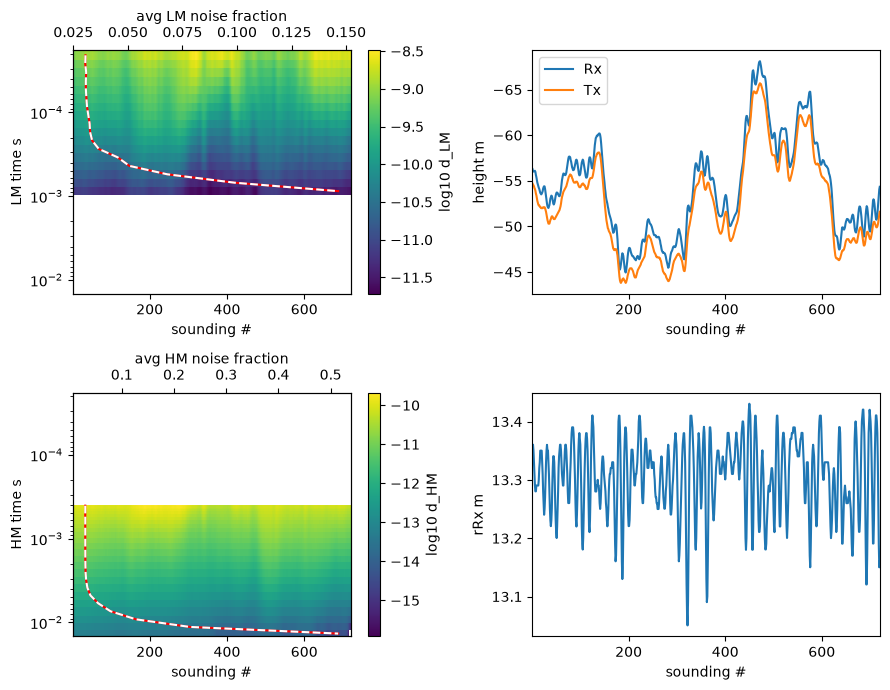

In [2]:
# datafile
fname_dat = "../00_required/SkyTEM_Menindee_full.dat"
zipsaveprefix = fname_dat
# electronics file with waveform, window times and filters
fname_specs_halt = "../00_required/skytem_electronics_halt.jl"
# column numbers from hdr file
X, Y, Z = 12, 13, 15
fid = 1
linenum = 2
frame_height = 9
frame_dx = 21
frame_dy = 22
frame_dz = 23
LM_Z = [26,42] # low moment columns
HM_Z = [43,67] # high moment columns
units = 1e-12  # V/(Am^2)
# read the electronics stuff from file
include(fname_specs_halt);
# create soundings array WITH **NO** decimation
soundings = transD_GP.SkyTEM1DInversion.read_survey_files(;fname_dat,
									 lowpassfcs, LM_times, HM_times, LM_ramp, HM_ramp,
									 LM_noise, HM_noise, rTx,
						             LM_Z, HM_Z, frame_height, frame_dz,
									 frame_dy, frame_dx, X, Y, Z, fid,
									 linenum,
                                     startfrom        = 1,
									 skipevery        = 1, ## **NO decimation!**
									 dotillsounding   = nothing,
									 units,
									 makeqcplots      = true);
@info "\nthere are $(length(soundings)) soundings"

# Discretisation and parameterisation options, same as synthetics

In [3]:
zfixed             = [-1e5]
ρfixed             = [1e12] # linear air resistivity Ωm
zstart             = 0.0
extendfrac         = 1.06   # percent extension
dz                 = 1.25   # thickness of first layer
nlayers            = 52     # number of layers in depth
ρbg                = 20     # linear air resistivity Ωm to check, not used in inversion
σ0                 = -2     # log 10 S/m background
lo                 = -2.5    # log10 S/m min conductivity
hi                 = 0.5     # log10 S/m max conductivity
# QC
showgeomplot       = false   # toggle to true see discretisation
plotfield          = false   # toggle to see forward model for ρbg

false

# Plot random sounding with aem operator

In [4]:
using Random
Random.seed!(111)
idxwell = rand(1:length(soundings)) # transD_GP.CommonToAll.getclosestidx(620436.75, 6428003, soundings)
aem, zall, = transD_GP.makeoperator(
    soundings[idxwell];
    zfixed, ρfixed, zstart, extendfrac,
    dz, ρbg, nlayers, plotfield, showgeomplot);

# Plot stored results

[ Info: 200613


idspec = idx[doesmatch] = 306


[ Info: X, Y = 621910.0, 6.4265774e6
[ Info: ϕd is 1.0


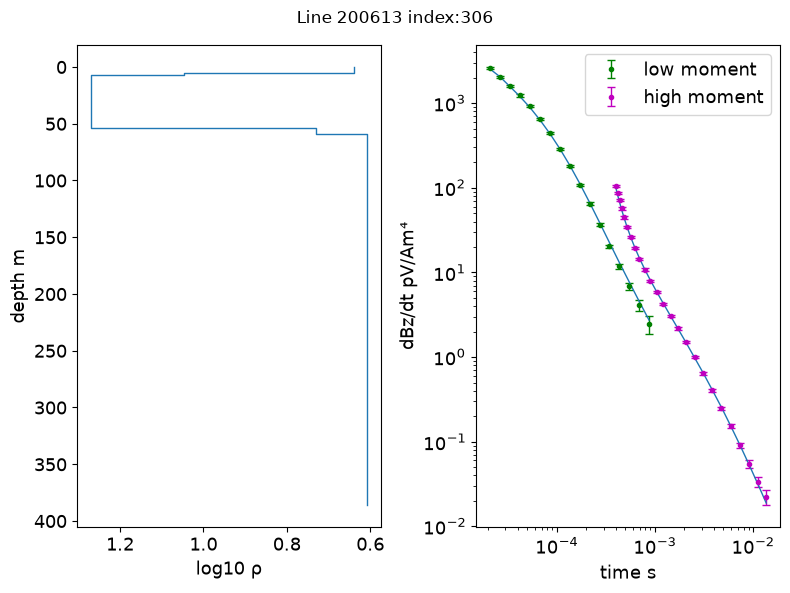

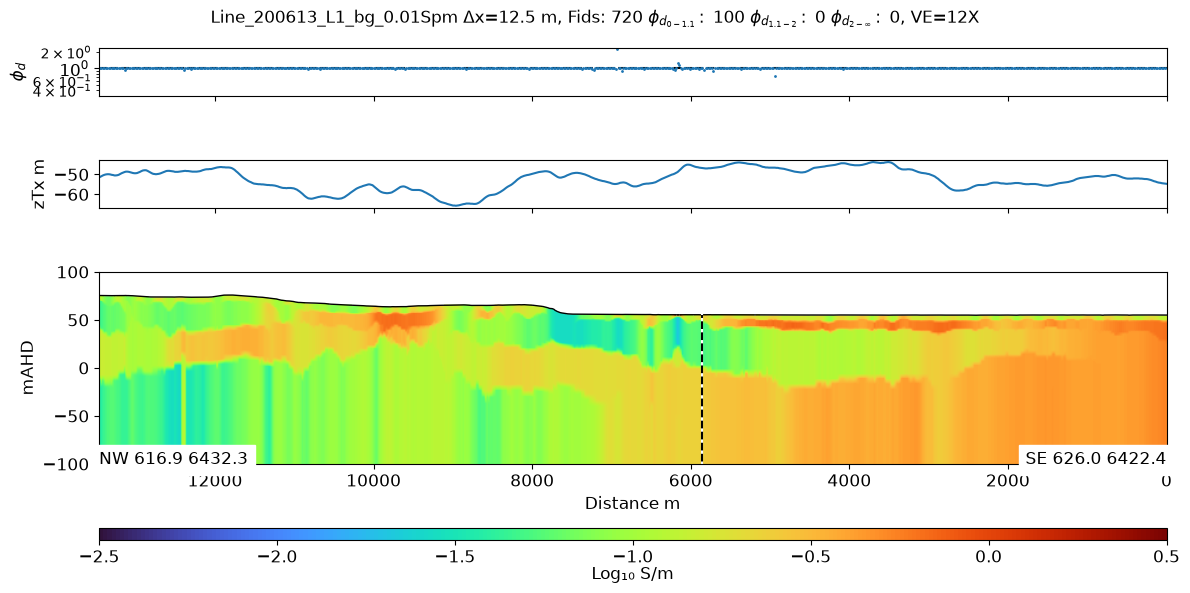

In [5]:
dr = 12.5 ## line interpolation distance in m
# plot result at particular idx and show results for whole line
yl=[-100,100] ## elevation plotting limits
transD_GP.plotconvandlast(soundings, dr, dz; zall, nnu=0,
    figsize=(12,6), vmin=lo, vmax=hi, postfix="L1_bg_$(round(10. ^σ0, sigdigits=4))Spm", prefix=zipsaveprefix,
    preferEright=true, showplot=true, logscale=true, yl,
    plotforward=true, aem_in=aem, idx=[idxwell], lnames=[200613]);

---

*This notebook was generated using [Literate.jl](https://github.com/fredrikekre/Literate.jl).*